# The per-unit twin: identity, off-body physics, and the pre-flight check

A calibrated `Robot` models a **design**. A `Twin` models **one physical unit**:
the calibrated body, *plus* the physics that happens off the body — servos heating,
a battery sagging — *plus* that unit's identity.

That combination is what lets the stack answer a question a body-only model
structurally cannot: **"will this command hurt this specific robot, and how long do
I have?"** MuJoCo will simulate a sustained hold perfectly and never mention that
the servo cooks at the end of it.

This notebook builds the twin of a real calibrated SO-101, watches it heat up under
load, turns that forecast into an OK/derate/veto decision that names its binding
constraint and a time-to-breach, does the same for battery brownout, and finishes
with `preflight` — verifying a candidate trajectory *before* it runs and binding the
verdict to the unit's attestation handle.

In [1]:
import contextlib
import io
import logging
import os
import sys

if os.path.basename(os.getcwd()) in ("examples", "scripts"):
    os.chdir("..")
sys.path.insert(0, os.getcwd())

with (
    contextlib.redirect_stdout(io.StringIO()),
    contextlib.redirect_stderr(io.StringIO()),
):
    # MuJoCo probes an optional NVIDIA Warp backend on import and prints when it is
    # absent; harmless (MJX falls back to JAX). mjx must be imported here too.
    import mujoco  # noqa: F401
    from mujoco import mjx  # noqa: F401

import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

logging.disable(logging.INFO)

from jaxterity.selfcheck import SafetyEnvelope, SafetyMonitor
from jaxterity.selfcheck.preflight import Scenario, constant_policy, preflight
from jaxterity.twin import Twin, TwinRollout, lekiwi_twin, so101_twin

twin = so101_twin("LK-REAL-001")
nv = twin.n_servos
nq = twin.robot.build_system()._nq

print(f"serial        : {twin.serial}")
print(f"servos (DOFs) : {nv}")
print(f"battery        : {twin.has_battery}")
print(f"ambient       : {twin.T_amb:.2f} K")
print(
    f"thermal leaves : C_th={twin.C_th[0]:.0f}  R_th={twin.R_th[0]:.0f}  k_pwr={twin.k_pwr[0]:.0f}"
)

serial        : LK-REAL-001
servos (DOFs) : 6
battery        : False
ambient       : 298.15 K
thermal leaves : C_th=15  R_th=4  k_pwr=6


## 1. This twin is wearing a real calibration

`so101_twin` builds on `zoo.calibrated("so100")`, and that calibration is not a
placeholder — it is the closed-loop friction fit from real LeKiwi telemetry worked
through in
[`calibrate_so101_real_telemetry.ipynb`](calibrate_so101_real_telemetry.ipynb).
The number below is the one identified there.

In [2]:
print(
    f"shoulder_pan viscous damping = "
    f"{float(twin.robot.joint_map['shoulder_pan'].damping):.4f}  (fitted, not frictionless)"
)
print(
    f"elbow_flex   viscous damping = "
    f"{float(twin.robot.joint_map['elbow_flex'].damping):.4f}"
)

shoulder_pan viscous damping = 0.4150  (fitted, not frictionless)
elbow_flex   viscous damping = 0.0674


## 2. Identity — the attestation handle

The handle is a per-unit content hash (ADR-008) extended over the off-body model. It
moves if the robot parameters move, if the off-body parameters move, if the serial
changes, or if the provenance changes.

Two units with *identical* parameters and different serials get **different**
handles. That is the point: a verdict earned by one physical robot must not silently
transfer to its twin on the next bench.

In [3]:
sibling = twin.with_serial("LK-REAL-002")
print(f"LK-REAL-001 : {twin.attestation_handle}")
print(f"LK-REAL-002 : {sibling.attestation_handle}")
print(f"distinct    : {twin.attestation_handle != sibling.attestation_handle}")

LK-REAL-001 : ecc7c75beefa64404478d747d5cc6e7750dcbcbe301f7ea3d95518e98698f297
LK-REAL-002 : 18d9d99109ccb6950eb39d462ecee44df2cf54acdfe628c49f3796f1dbabe18f
distinct    : True


## 3. Off-body physics: the servos get hot

Roll the twin forward under a constant holding torque. The arm barely moves — the
body-model view of this is "nothing is happening" — while the servo temperature
climbs on a first-order thermal model driven by the electrical power the hold costs.

Four holds, thirty seconds each:

In [4]:
dt, seconds = 0.02, 30.0
n_steps = int(seconds / dt)
q0, qd0 = jnp.zeros(nq), jnp.zeros(nv)
T0 = jnp.full(nv, twin.T_amb)

HOLDS = [0.3, 1.0, 1.5, 2.0]
rolls = {}
for hold in HOLDS:
    tau = jnp.tile(jnp.full(nv, hold), (n_steps, 1))
    rolls[hold] = twin.rollout(q0, qd0, T0, tau, dt)

print(f"{'hold (N*m)':<12}{'T after 30 s':>14}{'rise':>10}")
print("-" * 36)
for hold, out in rolls.items():
    Tf = float(out.temperature[-1].max())
    print(f"{hold:<12.1f}{Tf:>13.2f}K{Tf - twin.T_amb:>9.2f}K")

hold (N*m)    T after 30 s      rise
------------------------------------


0.3                299.00K     0.85K
1.0                307.59K     9.44K
1.5                319.40K    21.25K
2.0                335.92K    37.77K


Look at **1.5 N·m**: after thirty seconds it is +21 K, comfortably under the 35 K
ceiling we are about to declare. Watch the trace and you would ship it.

But it has not levelled off. Every one of these curves is still climbing, and where
each is *heading* is not on this plot. The 2.0 N·m hold gives the game away — it
crosses inside the window — while 1.5 N·m simply has not got there yet.

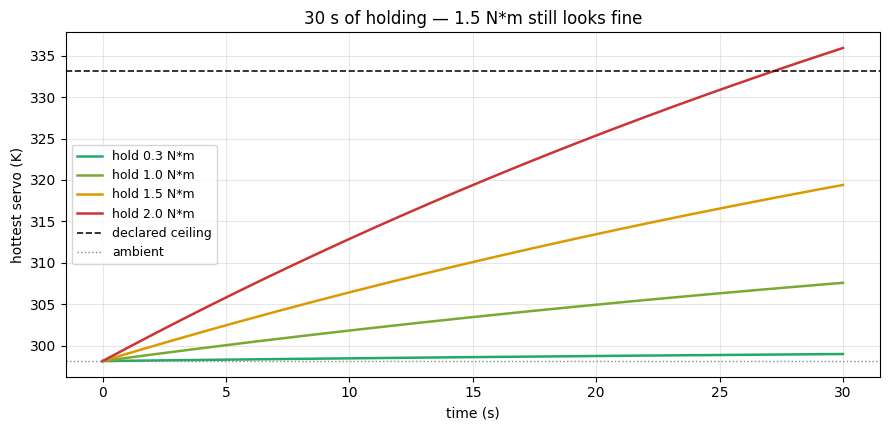

In [5]:
t = np.arange(n_steps + 1) * dt
CEILING = twin.T_amb + 35.0

fig, ax = plt.subplots(figsize=(9, 4.4))
for hold, c in zip(HOLDS, ["#2a6", "#7a3", "#d90", "#c33"], strict=True):
    ax.plot(
        t,
        np.asarray(rolls[hold].temperature).max(axis=1),
        lw=1.8,
        color=c,
        label=f"hold {hold} N*m",
    )
ax.axhline(CEILING, ls="--", color="#111", lw=1.2, label="declared ceiling")
ax.axhline(float(twin.T_amb), ls=":", color="#888", lw=1.0, label="ambient")
ax.set_xlabel("time (s)")
ax.set_ylabel("hottest servo (K)")
ax.set_title("30 s of holding — 1.5 N*m still looks fine")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## 4. The monitor: a decision, not a plot

`SafetyMonitor` takes the forecast plus the unit's own thermal leaves and answers
three things: **act or not**, **which constraint binds**, and **how long until it
breaches**. Crucially it does not just read the end of the rollout — it solves the
sustained-hold **steady state**, so it can veto a command whose 30-second trace still
looks harmless.

The operator declares the envelope. Here: 35 K above ambient.

In [6]:
envelope = SafetyEnvelope(temp_ceiling_k=twin.T_amb + 35.0)
monitor = SafetyMonitor(twin, envelope)


def flat_forecast(horizon=10, bus_v=None):
    "A short at-rest forecast; the monitor supplies the sustained-hold physics."
    return TwinRollout(
        q=jnp.zeros((horizon + 1, nq)),
        qd=jnp.zeros((horizon + 1, nv)),
        temperature=jnp.full((horizon + 1, nv), twin.T_amb),
        bus_voltage=None if bus_v is None else jnp.full(horizon, bus_v),
    )


print(f"{'hold':<8}{'action':<9}{'factor':>8}{'binding':>20}{'time to breach':>17}")
print("-" * 62)
for hold in [0.3, 1.0, 1.5, 1.8, 2.0, 2.5]:
    d = monitor.evaluate(flat_forecast(), action=jnp.full(nv, hold))
    ttb = "-" if d.time_to_breach_s is None else f"{d.time_to_breach_s:.1f} s"
    print(
        f"{hold:<8.1f}{d.action.name:<9}{d.factor:>8.2f}{d.binding_constraint:>20}{ttb:>17}"
    )

hold    action     factor             binding   time to breach
--------------------------------------------------------------


0.3     OK           1.00   servo_temperature                -
1.0     OK           1.00   servo_temperature                -
1.5     VETO         0.00   servo_temperature           62.7 s
1.8     VETO         0.00   servo_temperature           35.9 s
2.0     VETO         0.00   servo_temperature           27.2 s
2.5     VETO         0.00   servo_temperature           15.9 s


In [7]:
d = monitor.evaluate(flat_forecast(), action=jnp.full(nv, 1.5))
print("the 1.5 N*m hold - the one that looked fine at 30 s:\n")
print(f"  action            : {d.action.name}")
print(f"  binding constraint: {d.binding_constraint}")
print(
    f"  worst value       : {d.worst_value:.0f} K   (steady state, vs a "
    f"{CEILING:.0f} K ceiling)"
)
print(f"  time to breach    : {d.time_to_breach_s:.1f} s")
print(f"  detail            : {d.detail}")

the 1.5 N*m hold - the one that looked fine at 30 s:

  action            : VETO
  binding constraint: servo_temperature
  worst value       : 352 K   (steady state, vs a 333 K ceiling)
  time to breach    : 62.7 s
  detail            : veto: servo_temperature binding (worst 352) in 62.7 s


This is the argument for a per-unit twin in one line. That hold ended thirty seconds
of simulation at **319 K**, well inside a 333 K ceiling — and the monitor refuses it,
because the steady state it is walking toward is **352 K** and it breaches at
**62.7 s**. Simulating for thirty seconds and declaring victory would have shipped it.

The horizon you happened to simulate is not a safety property. The steady state is.

Two details worth noticing in the table: the veto arrives *with* a time-to-breach, so
it is actionable rather than merely obstructive — and the breach time shortens
monotonically with load (62.7 s → 35.9 s → 27.2 s → 15.9 s), which is the physics
behaving as it should.

## 5. A second constraint the body never sees: the pack

Temperature is not the only off-body state that ends a run. On a LeKiwi the whole arm
shares one battery, and a sustained multi-servo pull drags the bus down. `lekiwi_twin`
carries the Thévenin battery model (`V_oc`, `R_int`) alongside the thermal leaves.

Declare a bus floor and the same monitor now has two ways to say no — and it reports
*which* one bound.

In [8]:
lk = lekiwi_twin("LK-REAL-001")
bus_env = SafetyEnvelope(
    temp_ceiling_k=lk.T_amb + 200.0,  # deliberately slack: isolate the bus
    bus_floor_v=11.0,
)
bus_monitor = SafetyMonitor(lk, bus_env)

print(f"lekiwi twin has_battery = {lk.has_battery}\n")
print(f"{'forecast bus':<15}{'action':<9}{'binding':>18}{'worst':>10}")
print("-" * 53)
for bus in (12.0, 11.5, 10.5):
    fc = TwinRollout(
        q=jnp.zeros((11, nq)),
        qd=jnp.zeros((11, nv)),
        temperature=jnp.full((11, nv), lk.T_amb),
        bus_voltage=jnp.full(10, bus),
    )
    d = bus_monitor.evaluate(fc, action=jnp.full(nv, 0.3))
    print(
        f"{bus:<15.1f}{d.action.name:<9}{d.binding_constraint:>18}{d.worst_value:>10.2f}"
    )

lekiwi twin has_battery = True

forecast bus   action              binding     worst
-----------------------------------------------------
12.0           OK        servo_temperature    300.31
11.5           DERATE          bus_voltage     11.50
10.5           VETO            bus_voltage     10.50


A body-only model has no bus voltage at all, so this failure mode is not merely
missed — it is unrepresentable.

## 6. Pre-flight: check the trajectory before you run it

The monitor is an online guard. **Pre-flight** is the offline one: take a candidate
policy, simulate it against *this unit's* twin over declared scenarios, and return a
verdict — with the twin's attestation handle stamped on it.

In [9]:
scenario = Scenario(
    name="reach-and-hold",
    q0=tuple([0.0] * nv),
    qd0=tuple([0.0] * nv),
    T0=tuple([float(twin.T_amb)] * nv),
    n_steps=12,
    dt=0.02,
)
pf_env = SafetyEnvelope(temp_ceiling_k=twin.T_amb + 120.0)

for hold in (0.3, 2.5):
    rep = preflight(constant_policy(jnp.full(nv, hold)), twin, pf_env, [scenario])
    print(f"policy: constant {hold} N*m")
    print(f"  passed      : {rep.passed}")
    print(f"  bound to    : {rep.twin_handle[:24]}...")
    if not rep.passed:
        f = rep.failures[0]
        print(f"  failed on   : {f.name!r}")
        print(f"  because     : {f.decision.binding_constraint} ({f.decision.detail})")
    print()

policy: constant 0.3 N*m
  passed      : True
  bound to    : ecc7c75beefa64404478d747...



policy: constant 2.5 N*m
  passed      : False
  bound to    : ecc7c75beefa64404478d747...
  failed on   : 'reach-and-hold'
  because     : servo_temperature (veto: servo_temperature binding (worst 448) in 96.6 s)



## 7. Recalibrate the unit and the old pass expires

This is the property that makes the handle worth carrying. A pass is not a statement
about *a robot*; it is a statement about *this robot with these parameters*. Re-fit
the friction — because the unit aged, or because you captured better data — and the
handle moves, so any verdict bound to the old handle no longer describes the unit in
front of you.

In [10]:
policy = constant_policy(jnp.full(nv, 0.3))
prior = preflight(policy, twin, pf_env, [scenario])

refit = twin.robot.with_parameters({"shoulder_pan.damping": jnp.asarray(0.55)})
recal = Twin(
    refit,
    serial=twin.serial,
    C_th=twin.C_th,
    R_th=twin.R_th,
    k_pwr=twin.k_pwr,
    T_amb=twin.T_amb,
    servo_names=twin.servo_names,
)

print(f"prior pass       : {prior.passed}, bound to {prior.twin_handle[:20]}...")
print(
    f"recalibrated unit: same serial {recal.serial!r}, handle "
    f"{recal.attestation_handle[:20]}..."
)
print(f"handle changed   : {prior.twin_handle != recal.attestation_handle}")
print("\n=> the prior pass does not apply to the recalibrated unit; re-run preflight.")

after = preflight(policy, recal, pf_env, [scenario])
print(
    f"   re-run on the new handle: passed={after.passed}, "
    f"bound to {after.twin_handle[:20]}..."
)

prior pass       : True, bound to ecc7c75beefa64404478...
recalibrated unit: same serial 'LK-REAL-001', handle c1ee973c6f6252d06ddb...
handle changed   : True

=> the prior pass does not apply to the recalibrated unit; re-run preflight.


   re-run on the new handle: passed=True, bound to c1ee973c6f6252d06ddb...


## What this shows — and what it does not

**Shows.** A per-unit twin of a really-calibrated SO-101 forecasts an off-body state
the body model does not carry, converts it into a decision that names its binding
constraint and a time-to-breach, does the same for battery brownout, and binds
pre-flight verdicts to a unit identity that moves when the unit is re-fitted.

**Does not show.**

* **Predict-and-veto only.** There is no recovery controller here. The monitor
  refuses or derates a command; it does not adapt and continue. Graceful degradation
  is not demonstrated anywhere in this stack.
* **The envelope is declared, not learned.** `temp_ceiling_k` and `bus_floor_v` are
  operator inputs. Nothing here discovers a safe envelope on its own.
* **The thermal and battery leaves are a model.** `C_th`/`R_th`/`k_pwr` are
  representative defaults on this twin, not per-unit fits from a thermal capture of
  *your* servo. The battery Thévenin parameters were fit from a real LeKiwi load
  trace; the thermal ones on this builder were not.
* **One arm.** As everywhere in this stack: a single physical SO-101.

## Exercises

1. **Find the boundary.** Bisect the hold between 1.5 and 2.0 N*m to find where the
   decision flips OK → DERATE → VETO. Is the factor continuous across it?
2. **Tighten the envelope.** Drop `temp_ceiling_k` to ambient + 15 K. Which holds
   survive, and what happens to the reported time-to-breach?
3. **Make the bus bind first.** Give the LeKiwi twin a slack thermal ceiling and a
   high `bus_floor_v` so `bus_voltage` becomes the binding constraint under a hold
   that would otherwise be thermally fine.
4. **Break the binding.** Change something *other* than a joint parameter — the
   serial, or `T_amb` — and confirm the attestation handle still moves. Should a
   prior pass survive an ambient-temperature change? Argue both sides.

## Key takeaways

- **A twin is a robot plus the physics that happens off it plus an identity.** Drop
  any of the three and the safety question cannot be asked.
- **A 30-second rollout is not a safety verdict.** The 1.5 N*m hold finished the
  window at 319 K against a 333 K ceiling and was still climbing toward ~352 K; the
  steady-state check is what caught it. Whatever horizon you happened to simulate is
  not a property of the robot.
- **Decisions name their reason.** `binding_constraint` + `time_to_breach_s` is what
  makes a veto actionable instead of merely obstructive.
- **Verdicts are bound to a calibration, not to a robot.** Re-fit the unit and the
  handle moves, which expires every verdict that referenced it.